# Ring Attention from scratch: attention across devices

*Notebook 6 of 6. Prerequisites: the unnormalised merge from notebooks 1 and 4, and causal masking from notebook 5.*

**TL;DR.** Flash-style attention keeps the *activation memory* of one layer linear in the sequence length, but a single device still has to hold the whole sequence's queries, keys and values, so the maximum context is limited by one device's memory. Ring Attention (Liu, Zaharia and Abbeel, 2023, [arXiv:2310.01889](https://arxiv.org/abs/2310.01889)) removes that limit by sharding the sequence over $P$ devices arranged in a ring: each device keeps its query block and the K/V blocks travel around the ring, one hop per step, while each device merges the partial result for the block it currently holds into a running $(\tilde o,m,\ell)$ state. The communication of one hop can be hidden behind the computation of the previous one, provided the per-device block is long enough. We simulate $P$ devices in one process, verify exactness for three ways of sharding the sequence, measure the per-device memory and communication volume, quantify the load imbalance that causal masking creates (contiguous sharding keeps only 57% of the compute slots busy at $P=4$ in our counts), and test two fixes.

**Scope.** No real devices and no real interconnect. Communication is modelled as list rotation; timing statements use a stated model with assumed hardware numbers.

**Contents**
1. The ring, one step at a time
2. Exactness
3. Memory and communication volume
4. When communication hides behind compute
5. Causal masking breaks the balance
6. Fixing the balance: striped and zigzag sharding
7. What we did not do
8. Closing thoughts

In [1]:
import math, numpy as np, torch, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from fa_kit import *
torch.manual_seed(0); HEAD = {}; print('device:', DEVICE)

device: cpu


## 1. The ring, one step at a time

**A tiny example.** Four devices, sequence of 8 tokens, 2 tokens per device. Device $p$ owns query block $Q_p$ and starts with $K_p,V_p$. At step $t=0$ it computes attention of $Q_p$ against its own $K_p,V_p$. Then every device sends its current K/V block to the next device and receives one from the previous device. After $P=4$ steps every device has combined its queries with every K/V block exactly once. Device $p$ holds block $(p-t)\bmod P$ at step $t$.

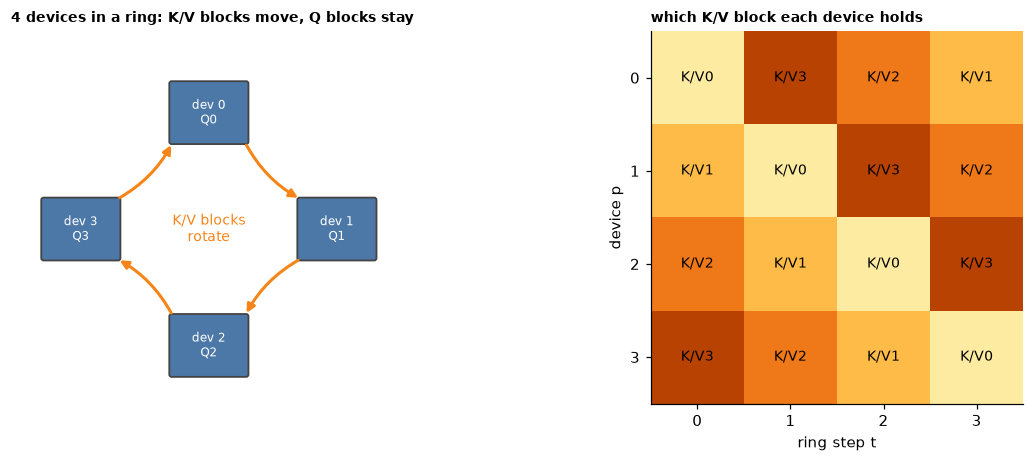

<sub>**Figure.** Left: Q never moves; K/V blocks travel one hop per step. Right: the table of blocks held. Notice that each row is a cyclic shift of the previous one and that every row contains each block exactly once, which is what guarantees that every query meets every key.</sub>

True

In [2]:
P = 4
held = np.array([[(p - t) % P for t in range(P)] for p in range(P)])     # held[p, t] = which K/V block device p has at step t
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axs[0]; ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.5, 1.7); ax.axis("off"); ax.set_aspect("equal"); ax.set_title("4 devices in a ring: K/V blocks move, Q blocks stay", loc="left", fontsize=9)
ang = [np.pi / 2 - 2 * np.pi * p / P for p in range(P)]; pos = [(1.1 * np.cos(a), 1.0 * np.sin(a)) for a in ang]
for p, (x, y) in enumerate(pos):
    box(ax, x - .34, y - .27, .68, .54, f"dev {p}\nQ{p}", COL["q"], tc="w", fs=8)
for p in range(P):
    (x0, y0), (x1, y1) = pos[p], pos[(p + 1) % P]; dx, dy = x1 - x0, y1 - y0; n = math.hypot(dx, dy)
    arrow(ax, (x0 + dx / n * .42, y0 + dy / n * .38), (x1 - dx / n * .42, y1 - dy / n * .38), color=COL["k"], lw=2, rad=.15)
ax.text(0, 0, "K/V blocks\nrotate", ha="center", va="center", fontsize=9, color=COL["k"])
ax = axs[1]; ax.imshow(held, cmap="YlOrBr", vmin=-1, vmax=P)
for p in range(P):
    for t in range(P): ax.text(t, p, f"K/V{held[p, t]}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(P)); ax.set_yticks(range(P)); ax.set_xlabel("ring step t"); ax.set_ylabel("device p"); ax.set_title("which K/V block each device holds", loc="left", fontsize=9)
plt.tight_layout(); plt.show()
caption("Left: Q never moves; K/V blocks travel one hop per step. Right: the table of blocks held. Notice that each row is a cyclic shift of the previous one and that every row contains each block exactly once, which is what guarantees that every query meets every key.")
check("each device sees every K/V block exactly once over P steps", all(sorted(held[p].tolist()) == list(range(P)) for p in range(P)))
check("at every step the P devices hold P distinct blocks (a permutation)", all(sorted(held[:, t].tolist()) == list(range(P)) for t in range(P)))

**General definition.** Let device $p$ own query positions $\mathcal I_p$ and K/V positions $\mathcal I_p$ (the same index set). Its running state $(\tilde O_p,m_p,\ell_p)$ is updated at step $t$ with the partial for the block of source $s=(p-t)\bmod P$, using the associative merge of notebook 4:

$$(\tilde O_p,m_p,\ell_p)\leftarrow(\tilde O_p,m_p,\ell_p)\oplus\mathrm{partial}(Q_p,K_s,V_s),\qquad O_p=\tilde O_p/\ell_p\ \text{at the end}.$$

**How it is implemented.** The code below keeps one list entry per device, applies the partial for the block each device currently holds, then rotates the K/V list by one position (the stand-in for a point-to-point send/receive). Masking uses global positions, so any assignment of tokens to devices is supported.

In [3]:
def partial2d(q, Kc, Vc, valid):
    """Partial attention of q against one K/V block. valid:(nq,nk) bool or None. Returns (O~, m, l)."""
    S = (q @ Kc.T) / math.sqrt(q.shape[1])
    if valid is not None: S = S.masked_fill(~valid, -float("inf"))
    m = S.max(1).values; ms = torch.where(torch.isinf(m), torch.zeros_like(m), m); Pm = torch.exp(S - ms[:, None]); return Pm @ Vc, m, Pm.sum(1)

def merge_unnormalised(a, b):
    m = torch.maximum(a[1], b[1]); ms = torch.where(torch.isinf(m), torch.zeros_like(m), m); sa, sb = torch.exp(a[1] - ms), torch.exp(b[1] - ms)
    return sa[:, None] * a[0] + sb[:, None] * b[0], m, sa * a[2] + sb * b[2]

def shard(N, P, scheme):
    """Global token indices owned by each device."""
    if scheme == "contiguous": c = N // P; return [torch.arange(p * c, (p + 1) * c) for p in range(P)]
    if scheme == "striped":    return [torch.arange(p, N, P) for p in range(P)]                         # token i -> device i mod P
    if scheme == "zigzag":     c = N // (2 * P); return [torch.cat([torch.arange(p * c, (p + 1) * c), torch.arange((2 * P - 1 - p) * c, (2 * P - p) * c)]) for p in range(P)]
    raise ValueError(scheme)

def ring_attention(q, k, v, P, scheme="contiguous", causal=True):
    """Simulated Ring Attention over P devices. Returns (O (N,d), work[t][p] = number of allowed (q,k) pairs computed, comm elements per device)."""
    N, d = q.shape; idx = shard(N, P, scheme)
    Qs = [q[i] for i in idx]; kv = [(k[i], v[i], i) for i in idx]                                       # what each device currently holds
    state = [(torch.zeros(len(i), d, dtype=q.dtype), torch.full((len(i),), -float("inf"), dtype=q.dtype), torch.zeros(len(i), dtype=q.dtype)) for i in idx]
    work = np.zeros((P, P)); comm = 0
    for t in range(P):
        for p in range(P):
            Kc, Vc, pos_kv = kv[p]; valid = (idx[p][:, None] >= pos_kv[None, :]) if causal else None
            work[t, p] = valid.sum().item() if causal else len(idx[p]) * len(pos_kv)
            if work[t, p] == 0: continue                                                                # fully masked block: skip the compute
            state[p] = merge_unnormalised(state[p], partial2d(Qs[p], Kc, Vc, valid))
        if t < P - 1: comm += 2 * kv[0][0].numel(); kv = [kv[(p - 1) % P] for p in range(P)]            # send K,V to next device, receive from previous
    out = torch.zeros(N, d, dtype=q.dtype)
    for p in range(P): O_, m_, l_ = state[p]; out[idx[p]] = O_ / torch.where(l_ == 0, torch.ones_like(l_), l_)[:, None]
    return out, work, comm

## 2. Exactness

We check the simulated ring against dense float64 attention for several device counts, both masks and all three sharding schemes (sections 5 and 6 explain the last two). We also check that gradients flowing through the ring match dense autograd; this uses PyTorch's autograd through the simulation, not a hand-written ring backward (section 7).

In [4]:
N, d = 256, 32; q, k, v = (torch.randn(N, d, dtype=torch.float64) for _ in range(3))
for P_ in (1, 2, 4, 8):
    for scheme in ("contiguous", "striped", "zigzag"):
        for causal in (False, True):
            O_, _, _ = ring_attention(q, k, v, P_, scheme, causal); e = max_err(O_, ref_attention(q, k, v, causal=causal)[0])
            check(f"ring P={P_} {scheme:<10} causal={causal}: == dense", e < 1e-11, f"err={e:.1e}")
q_, k_, v_ = (torch.randn(64, 16, dtype=torch.float64, requires_grad=True) for _ in range(3)); dO = torch.randn(64, 16, dtype=torch.float64)
(ring_attention(q_, k_, v_, 4, "zigzag", True)[0] * dO).sum().backward(); g1 = [t.grad.clone() for t in (q_, k_, v_)]
for t in (q_, k_, v_): t.grad = None
(ref_attention(q_, k_, v_, causal=True)[0] * dO).sum().backward(); g2 = [t.grad for t in (q_, k_, v_)]
e = max(max_err(a, b) for a, b in zip(g1, g2)); print("gradient error through the ring (autograd):", e); check("gradients through the simulated ring match dense autograd", e < 1e-11)

gradient error through the ring (autograd): 1.1102230246251565e-15


True

The ring is exact for every configuration we tried. Next, the point of the exercise: what each device needs to hold and send.

## 3. Memory and communication volume

**A tiny example.** With $N=8192$ tokens, $d=64$ and $P=8$ devices each device owns $c=1024$ tokens. It holds $Q_p$ ($c\,d$), its running $\tilde O_p$ ($c\,d$), $m_p,\ell_p$ ($2c$), the K/V block it is computing on ($2cd$) and the K/V block arriving for the next step ($2cd$): $6cd+2c$ elements. A device running flash attention on the whole sequence alone holds $Q,K,V,O$: $4Nd$.

**General definition.** Per-device resident elements: $6cd+2c$ with $c=N/P$, i.e. a fraction $\approx 1.5/P$ of the single-device footprint. Per-device communication over the whole ring: $(P-1)\cdot 2cd=2Nd\,(P-1)/P$ elements sent and the same received, which is almost independent of $P$.

      N   P | resident/device (M elems) | vs single device | comm/device (M elems)
   4096   1 |                      1.58 |            1.508 |       0.00
   4096   4 |                      0.40 |            0.377 |       0.39
   4096  16 |                      0.10 |            0.094 |       0.49
  16384   1 |                      6.32 |            1.508 |       0.00
  16384   4 |                      1.58 |            0.377 |       1.57
  16384  16 |                      0.40 |            0.094 |       1.97
  65536   1 |                     25.30 |            1.508 |       0.00
  65536   4 |                      6.32 |            0.377 |       6.29
  65536  16 |                      1.58 |            0.094 |       7.86


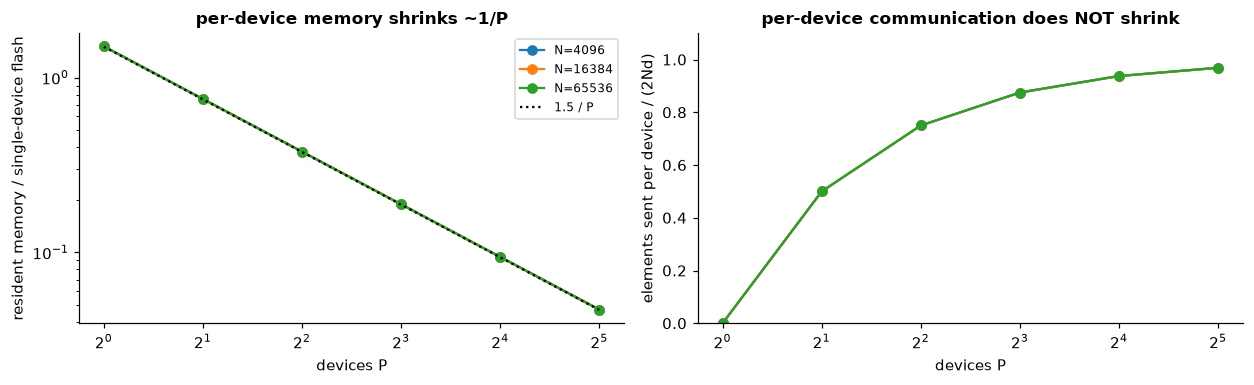

<sub>**Figure.** Left: resident memory follows the dotted 1.5/P line, so the achievable context length grows linearly with the number of devices. Right: but each device still has to receive almost 2Nd elements in total, approaching 1.0 on this axis as P grows. Notice that this is the cost side of the same coin: computation per device shrinks like 1/P (next section) while communication per device does not, so at some P the ring becomes communication-bound.</sub>

True

In [5]:
d = 64; Ns = [4096, 16384, 65536]; Ps = [1, 2, 4, 8, 16, 32]
def resident(N, P, d): c = N // P; return 6 * c * d + 2 * c
def comm_per_device(N, P, d): c = N // P; return (P - 1) * 2 * c * d
# verify the closed forms against the simulation's own counters
q_, k_, v_ = (torch.randn(512, 16, dtype=torch.float64) for _ in range(3))
for P_ in (2, 4, 8):
    _, _, comm = ring_attention(q_, k_, v_, P_, "contiguous", False); check(f"counted comm == (P-1)*2*c*d for P={P_}", comm == comm_per_device(512, P_, 16))
print(f"{'N':>7} {'P':>3} | resident/device (M elems) | vs single device | comm/device (M elems)")
for N_ in Ns:
    for P_ in Ps[::2]: print(f"{N_:>7} {P_:>3} | {resident(N_, P_, d)/1e6:>25.2f} | {resident(N_, P_, d)/(4*N_*d):>16.3f} | {comm_per_device(N_, P_, d)/1e6:>10.2f}")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6))
for N_, c_ in zip(Ns, ("#1f77b4", "#ff7f0e", "#2ca02c")):
    axs[0].plot(Ps, [resident(N_, P_, d) / (4 * N_ * d) for P_ in Ps], "o-", color=c_, label=f"N={N_}"); axs[1].plot(Ps, [comm_per_device(N_, P_, d) / (2 * N_ * d) for P_ in Ps], "o-", color=c_, label=f"N={N_}")
axs[0].plot(Ps, [1.5 / P_ for P_ in Ps], "k:", label="1.5 / P"); axs[0].set_xscale("log", base=2); axs[0].set_yscale("log"); axs[0].set_xlabel("devices P"); axs[0].set_ylabel("resident memory / single-device flash"); axs[0].legend(fontsize=8); axs[0].set_title("per-device memory shrinks ~1/P")
axs[1].set_xscale("log", base=2); axs[1].set_xlabel("devices P"); axs[1].set_ylabel("elements sent per device / (2Nd)"); axs[1].set_ylim(0, 1.1); axs[1].set_title("per-device communication does NOT shrink")
plt.tight_layout(); plt.show()
caption("Left: resident memory follows the dotted 1.5/P line, so the achievable context length grows linearly with the number of devices. Right: but each device still has to receive almost 2Nd elements in total, approaching 1.0 on this axis as P grows. Notice that this is the cost side of the same coin: computation per device shrinks like 1/P (next section) while communication per device does not, so at some P the ring becomes communication-bound.")
check("resident memory is ~1.5/P of single-device (within 5%) for N=65536, P=8", abs(resident(65536, 8, d) / (4 * 65536 * d) - 1.5 / 8) < 0.05 * 1.5 / 8)
check("comm per device approaches 2Nd as P grows", comm_per_device(65536, 32, d) / (2 * 65536 * d) > 0.96)

## 4. When communication hides behind compute

**A tiny example.** At each step a device computes attention between $c$ queries and $c$ keys: $4c^2d$ FLOPs per head-dimension slice (non-causal). At the same time it must send and receive a K/V block of $2cd$ elements, i.e. $2cd\cdot b$ bytes for element size $b$. If the compute takes at least as long as the transfer, the transfer is free.

**General definition.** With compute rate $F$ FLOP/s and link bandwidth $B$ byte/s per direction,

$$\frac{t_{\text{compute}}}{t_{\text{comm}}}=\frac{4c^2d/F}{2cd\,b/B}=\frac{2c\,B}{F\,b}\ \ge 1\iff c\ge\frac{F\,b}{2B}.$$

The Ring Attention paper states the corresponding condition on block size in terms of FLOPs and bandwidth; the form above is our own derivation for fp16 attention with $b=2$, so $c\ge F/B$.

**Assumed hardware for the example (not measured; chosen to be round and plausible).** Compute $F=156$ TFLOP/s (about 50% of an A100's 312 TFLOP/s peak, an assumed utilisation); intra-node link $B=300$ GB/s per direction (NVLink-class, recalled); inter-node link $B=25$ GB/s (a 200 Gb/s network, recalled).

NVLink-class 300 GB/s   : ring overlaps compute when block c >=      520 tokens per device
inter-node 25 GB/s      : ring overlaps compute when block c >=     6240 tokens per device
slow 5 GB/s             : ring overlaps compute when block c >=    31200 tokens per device

       N    P       c | link | compute ms/step | comm ms/step | overlapped total ms | not overlapped ms
  131072    8   16384 | NVLink-class 3 |         28.193 |        0.895 |              225.54 |            232.70  
  131072   64    2048 | NVLink-class 3 |          0.441 |        0.112 |               28.19 |             35.35  
  131072   64    2048 | inter-node 25  |          0.441 |        1.342 |               85.90 |            114.09  (comm-bound)
 1048576   64   16384 | inter-node 25  |         28.193 |       10.737 |             1804.33 |           2491.52  
  131072  512     256 | inter-node 25  |          0.007 |        0.168 |               85.90 |             89.42  (comm-bound)


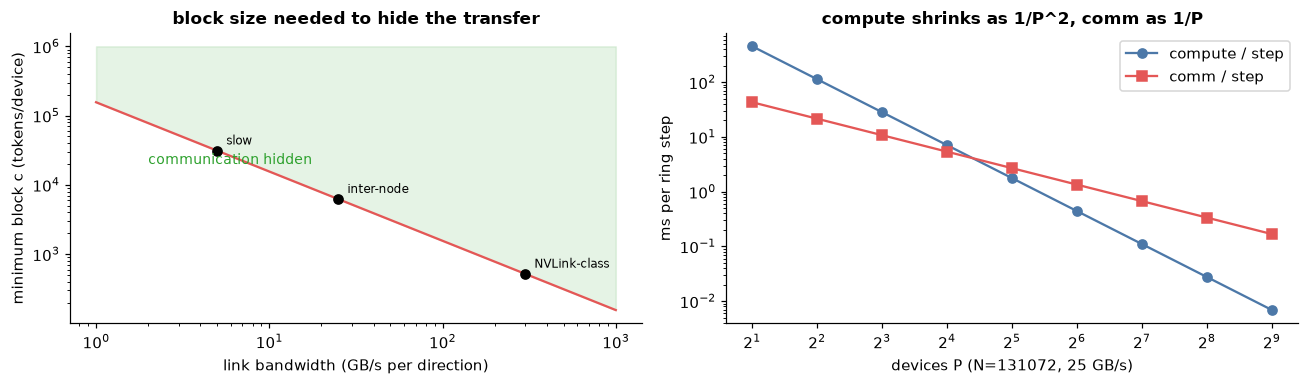

<sub>**Figure.** Left: the shaded region is where one hop's transfer is shorter than one step's compute; at NVLink speed that needs about 520 tokens per device, at 25 GB/s about 6240 (our assumed numbers). Right: at fixed N the compute per step falls with the square of P (both queries and keys per block shrink) but the transfer per step falls only linearly, so the curves cross; here between P=16 and P=32 (c is about 6240 at P=21). Notice that this crossing, not memory, is what limits how far one can scale a ring for a given N.</sub>

In [6]:
F = 156e12; b = 2
def c_required(Bw): return F * b / (2 * Bw)
links = {"NVLink-class 300 GB/s": 300e9, "inter-node 25 GB/s": 25e9, "slow 5 GB/s": 5e9}
for nm, Bw in links.items(): print(f"{nm:<24}: ring overlaps compute when block c >= {c_required(Bw):>8.0f} tokens per device")
check("derived overlap threshold equals F/B for fp16", abs(c_required(300e9) - F / 300e9) < 1e-6)
def step_times(N, P, Bw, d=128, H=32):
    c = N // P; tc = 4 * c * c * H * d / F; tm = 2 * c * H * d * b / Bw; return tc, tm
print(f"\n{'N':>8} {'P':>4} {'c':>7} | link | compute ms/step | comm ms/step | overlapped total ms | not overlapped ms")
rows = []
for N_, P_, ln in [(131072, 8, "NVLink-class 300 GB/s"), (131072, 64, "NVLink-class 300 GB/s"), (131072, 64, "inter-node 25 GB/s"), (1048576, 64, "inter-node 25 GB/s"), (131072, 512, "inter-node 25 GB/s")]:
    tc, tm = step_times(N_, P_, links[ln]); ov, nov = P_ * max(tc, tm), P_ * (tc + tm); rows.append((N_, P_, ln, tc, tm, ov, nov))
    print(f"{N_:>8} {P_:>4} {N_//P_:>7} | {ln[:14]:<14} | {tc*1e3:>14.3f} | {tm*1e3:>12.3f} | {ov*1e3:>19.2f} | {nov*1e3:>17.2f}  {'(comm-bound)' if tm > tc else ''}")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
Bws = np.logspace(9, 12, 100); axs[0].plot(Bws / 1e9, [c_required(x) for x in Bws], color=COL["o"]); axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("link bandwidth (GB/s per direction)"); axs[0].set_ylabel("minimum block c (tokens/device)")
for nm, Bw in links.items(): axs[0].plot([Bw / 1e9], [c_required(Bw)], "ko"); axs[0].annotate(nm.split()[0], (Bw / 1e9, c_required(Bw)), textcoords="offset points", xytext=(6, 4), fontsize=8)
axs[0].set_title("block size needed to hide the transfer"); axs[0].fill_between(Bws / 1e9, [c_required(x) for x in Bws], 1e6, color=COL["good"], alpha=.12); axs[0].text(2, 2e4, "communication hidden", color=COL["good"], fontsize=9)
Pl = [2, 4, 8, 16, 32, 64, 128, 256, 512]; Nfix = 131072
axs[1].plot(Pl, [step_times(Nfix, P_, 25e9)[0] * 1e3 for P_ in Pl], "o-", color=COL["q"], label="compute / step"); axs[1].plot(Pl, [step_times(Nfix, P_, 25e9)[1] * 1e3 for P_ in Pl], "s-", color=COL["o"], label="comm / step")
axs[1].set_xscale("log", base=2); axs[1].set_yscale("log"); axs[1].set_xlabel("devices P (N=131072, 25 GB/s)"); axs[1].set_ylabel("ms per ring step"); axs[1].legend(); axs[1].set_title("compute shrinks as 1/P^2, comm as 1/P")
plt.tight_layout(); plt.show()
caption("Left: the shaded region is where one hop's transfer is shorter than one step's compute; at NVLink speed that needs about 520 tokens per device, at 25 GB/s about 6240 (our assumed numbers). Right: at fixed N the compute per step falls with the square of P (both queries and keys per block shrink) but the transfer per step falls only linearly, so the curves cross; here between P=16 and P=32 (c is about 6240 at P=21). Notice that this crossing, not memory, is what limits how far one can scale a ring for a given N.")
check("at P=8 over NVLink-class the ring is compute-bound (comm hidden)", rows[0][3] > rows[0][4]); check("at P=512 on 25 GB/s the ring is comm-bound", rows[4][4] > rows[4][3])
HEAD["rows"] = rows

The conditions above assume every block needs the same compute. Causal masking breaks that assumption, as we now measure.

## 5. Causal masking breaks the balance

**A tiny example.** With contiguous sharding and 4 devices, device 0 owns the first quarter of the tokens and device 3 the last. A causal query in device 0 can only see keys in device 0's own block; a query in device 3 sees all four blocks. So at step $t$ device $p$'s block of source $(p-t)\bmod 4$ is: fully allowed if the source precedes $p$, triangular if it is $p$ itself, and completely masked if the source comes after $p$ (those blocks are skipped).

**General definition.** The ring is synchronous: at each step every device waits for the slowest one before the next hop. Let $w_{t,p}$ be the work (allowed query-key pairs) of device $p$ at step $t$. Then

$$\text{makespan}\propto\sum_t\max_p w_{t,p},\qquad \text{efficiency}=\frac{\sum_{t,p}w_{t,p}}{P\sum_t\max_p w_{t,p}} .$$

This models element-level skipping and uses pair counts as time; real kernels are tile-granular (notebook 5), so it is an upper bound on balance.

contiguous : efficiency =  57.2%   (per-step max work [2080, 4096, 4096, 4096], mean [2080, 3072, 2048, 1024])
striped    : efficiency =  98.8%   (per-step max work [2080, 2080, 2080, 2080], mean [2080, 2064, 2048, 2032])
zigzag     : efficiency = 100.0%   (per-step max work [2080, 2048, 2048, 2048], mean [2080, 2048, 2048, 2048])


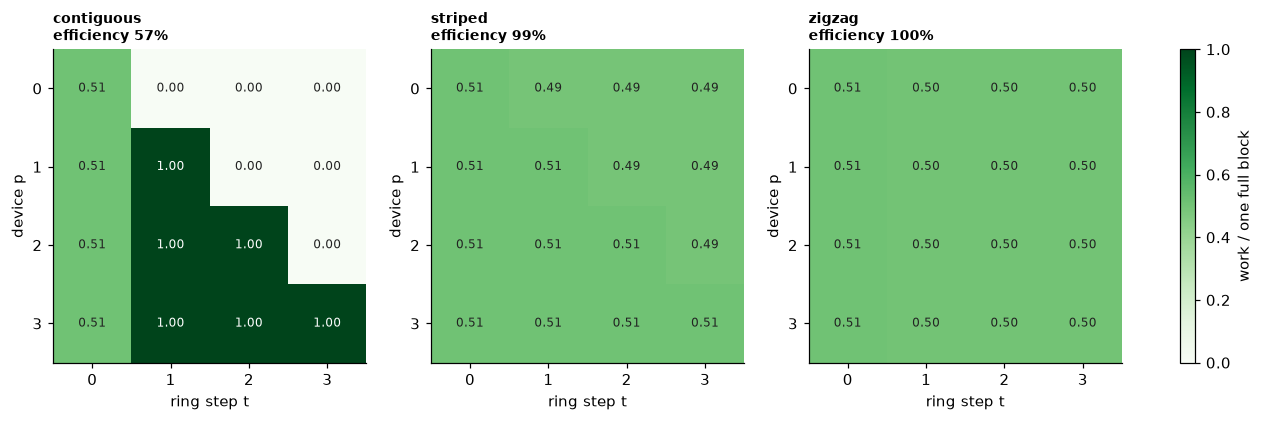

<sub>**Figure.** Each cell is the fraction of a full c x c block that a device must compute at a step (dark = busy, white = idle). Contiguous sharding (left) is triangular: at step 0 every device does a half block, at later steps the high-numbered devices do full blocks while the low-numbered ones sit idle, and the step time is set by the busiest device. Striped and zigzag (middle, right) give every device nearly the same load at every step. Notice that the left panel's total work is identical to the others; only its distribution differs.</sub>

In [7]:
N, d, P = 256, 16, 4; q, k, v = (torch.randn(N, d, dtype=torch.float64) for _ in range(3))
def efficiency(work): return work.sum() / (work.shape[1] * work.max(axis=1).sum())
works = {}
for scheme in ("contiguous", "striped", "zigzag"):
    _, w, _ = ring_attention(q, k, v, P, scheme, True); works[scheme] = w
    print(f"{scheme:<11}: efficiency = {efficiency(w)*100:5.1f}%   (per-step max work {w.max(axis=1).astype(int).tolist()}, mean {w.mean(axis=1).round(0).astype(int).tolist()})")
fig, axs = plt.subplots(1, 3, figsize=(13.5, 3.7))
full_block = (N // P) ** 2
for ax, (scheme, w) in zip(axs, works.items()):
    im = ax.imshow((w / full_block).T, cmap="Greens", vmin=0, vmax=1); ax.set_title(f"{scheme}\nefficiency {efficiency(w)*100:.0f}%", fontsize=9, loc="left"); ax.set_xlabel("ring step t"); ax.set_ylabel("device p"); ax.set_xticks(range(P)); ax.set_yticks(range(P))
    for t in range(P):
        for p in range(P): ax.text(t, p, f"{w[t, p]/full_block:.2f}", ha="center", va="center", fontsize=8, color="w" if w[t, p] / full_block > .55 else COL["ink"])
plt.colorbar(im, ax=axs, fraction=.02, label="work / one full block"); plt.show()
caption("Each cell is the fraction of a full c x c block that a device must compute at a step (dark = busy, white = idle). Contiguous sharding (left) is triangular: at step 0 every device does a half block, at later steps the high-numbered devices do full blocks while the low-numbered ones sit idle, and the step time is set by the busiest device. Striped and zigzag (middle, right) give every device nearly the same load at every step. Notice that the left panel's total work is identical to the others; only its distribution differs.")
check("contiguous causal efficiency matches the closed form P/(2P-1) within 2%", abs(efficiency(works["contiguous"]) - P / (2 * P - 1)) < 0.02, f"{efficiency(works['contiguous']):.3f} vs {P/(2*P-1):.3f}")
HEAD["works"] = works; HEAD["eff"] = {s_: efficiency(w) for s_, w in works.items()}

We found that contiguous sharding keeps 57% of the compute slots useful at $P=4$. The closed form follows from the structure: step 0 costs half a block ($c^2/2$, the triangular diagonal blocks), every later step is set by a device holding a full block ($c^2$), and the total work is $P^2c^2/2$, so the efficiency is $\frac{P^2c^2/2}{P\,(c^2/2+(P-1)c^2)}=\frac{P}{2P-1}$, which is $4/7=0.571$ at $P=4$ and falls toward 50% as $P$ grows: for a causal model nearly half of the ring's compute time is wasted on idling.

## 6. Fixing the balance: striped and zigzag sharding

**A tiny example.** *Striped* sharding (Brandon et al., 2023, [arXiv:2311.09431](https://arxiv.org/abs/2311.09431)) assigns token $i$ to device $i\bmod P$, so every device holds tokens from the whole sequence. Any pair of blocks then looks like a half-masked (triangular-ish) block, so every device has nearly equal work at every step. *Zigzag* sharding splits the sequence into $2P$ chunks and gives device $p$ chunks $p$ and $2P-1-p$, a head and a tail, so a heavy chunk is always paired with a light one. (We implement both; the zigzag scheme is, to our recollection, used in public ring-attention implementations, which we have not checked.)

**Scaling of efficiency.** We measure the efficiency as $P$ grows.

  P |  contiguous |     striped |      zigzag | closed form P/(2P-1)
  2 |       66.7% |       99.9% |      100.0% | 66.7%
  4 |       57.2% |       99.7% |      100.0% | 57.1%
  8 |       53.4% |       99.3% |      100.0% | 53.3%
 16 |       51.6% |       98.6% |      100.0% | 51.6%


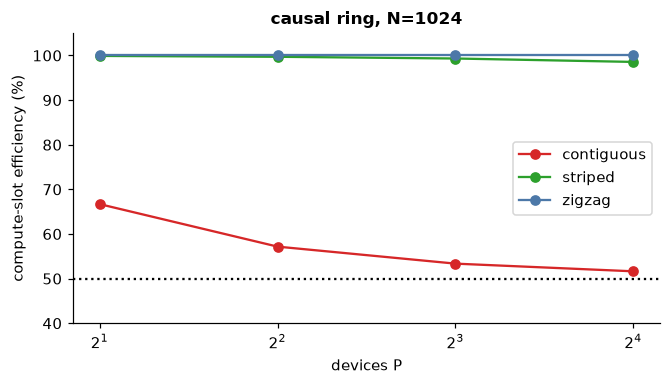

<sub>**Figure.** Contiguous sharding decays toward 50% as P grows; both alternatives stay close to 100% in this model. Notice the cost hidden in this plot: a striped or zigzag layout requires the data (and, in training, the labels and position information) to be permuted into that layout before the first layer and back afterwards, and RoPE positions must use global indices, which our simulation handles by carrying the index arrays.</sub>

In [8]:
N = 1024; q, k, v = (torch.randn(N, 8, dtype=torch.float64) for _ in range(3)); eff = {s_: [] for s_ in works}; Pl = [2, 4, 8, 16]
for P_ in Pl:
    for s_ in eff: _, w, _ = ring_attention(q, k, v, P_, s_, True); eff[s_].append(efficiency(w))
print(f"{'P':>3} | " + " | ".join(f"{s_:>11}" for s_ in eff) + " | closed form P/(2P-1)")
for i, P_ in enumerate(Pl): print(f"{P_:>3} | " + " | ".join(f"{eff[s_][i]*100:>10.1f}%" for s_ in eff) + f" | {P_/(2*P_-1)*100:.1f}%")
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for s_, c_ in zip(eff, (COL["bad"], COL["good"], COL["q"])): ax.plot(Pl, [e * 100 for e in eff[s_]], "o-", color=c_, label=s_)
ax.axhline(50, color="k", ls=":"); ax.set_xscale("log", base=2); ax.set_xlabel("devices P"); ax.set_ylabel("compute-slot efficiency (%)"); ax.set_ylim(40, 105); ax.legend(); ax.set_title("causal ring, N=1024")
plt.tight_layout(); plt.show()
caption("Contiguous sharding decays toward 50% as P grows; both alternatives stay close to 100% in this model. Notice the cost hidden in this plot: a striped or zigzag layout requires the data (and, in training, the labels and position information) to be permuted into that layout before the first layer and back afterwards, and RoPE positions must use global indices, which our simulation handles by carrying the index arrays.")
check("striped and zigzag efficiency >= 90% for all tested P", all(e >= .9 for s_ in ("striped", "zigzag") for e in eff[s_]))
check("contiguous efficiency is below 70% at P=16", eff["contiguous"][-1] < .7)
HEAD["eff_scale"] = eff

**Cost of the fix, measured.** The balanced layouts do not change the total work or the communication volume (same sums in the work matrix and the same counted bytes), so their only costs are the data permutation and the loss of a very simple mask structure: within a block pair the mask is a *shifted triangle* rather than all-or-nothing, so almost every block is partial in the sense of notebook 5. We count that directly.

In [9]:
N, P = 256, 4; idx_c = {s_: shard(N, P, s_) for s_ in ("contiguous", "striped", "zigzag")}
print(f"{'scheme':<11} | blocks full / partial / empty (of {P*P})   | total allowed pairs | comm elems/device")
for s_, idx in idx_c.items():
    cnt = [0, 0, 0]
    for p in range(P):
        for sidx in range(P):
            valid = idx[p][:, None] >= idx[sidx][None, :]; cnt[0 if valid.all() else (2 if not valid.any() else 1)] += 1
    _, w, comm = ring_attention(q[:N], k[:N], v[:N], P, s_, True); print(f"{s_:<11} | {cnt[0]:>5} / {cnt[1]:>3} / {cnt[2]:>3}                       | {int(w.sum()):>19} | {comm}")
    check(f"{s_}: total allowed pairs == N(N+1)/2", int(w.sum()) == N * (N + 1) // 2)

scheme      | blocks full / partial / empty (of 16)   | total allowed pairs | comm elems/device
contiguous  |     6 /   4 /   6                       |               32896 | 3072
striped     |     0 /  16 /   0                       |               32896 | 3072
zigzag      |     0 /  16 /   0                       |               32896 | 3072


Same pairs, same communication, but contiguous sharding has full and empty blocks (cheap to handle, skip or no mask) whereas the balanced layouts turn almost every block into a partial one that needs an element mask. That is the trade: balance for mask handling.

## 7. What we did not do

* **No real communication.** Rotation is a list shift. We did not overlap `send`/`recv` with compute, handle latency, topology, or failures.
* **No hand-written ring backward.** Gradients are exact through autograd of the simulation, but a real implementation circulates $dK,dV$ with the K/V blocks and recomputes tiles as in notebook 1; we did not implement it.
* **No per-device flash kernel.** Each "device" computes its partial with a dense block (`partial2d`) rather than a tiled kernel, so the within-device memory is $O(c^2)$ per step in our code even though a real implementation would keep it $O(c)$.
* **Hardware numbers are assumed**, as stated in section 4.
* **Alternatives not compared:** all-to-all sequence parallelism (DeepSpeed-Ulysses, Jacobs et al., 2023, [arXiv:2309.14509](https://arxiv.org/abs/2309.14509)) shards heads instead of the ring and has a different communication pattern; we have not implemented or compared it.

## 8. Closing thoughts

In [10]:
e = HEAD["eff"]; r = HEAD["rows"]
display(Markdown(f"""
| quantity | value | how obtained |
|---|---|---|
| exactness vs dense float64 (P up to 8, 3 shardings, causal and not) | all pass, error < 1e-11 | measured |
| per-device resident memory, N=65536, P=8 | {resident(65536, 8, 64)/(4*65536*64):.3f} of single-device (1.5/P = {1.5/8:.3f}) | counted formula, checked against counters |
| per-device communication, P=32 | {comm_per_device(65536, 32, 64)/(2*65536*64):.2f} x (2Nd) | counted formula |
| overlap threshold, c >= F/B | 520 tokens at 300 GB/s, 6240 at 25 GB/s | derived, assumed F=156 TFLOP/s |
| causal ring efficiency, P=4: contiguous / striped / zigzag | {e['contiguous']*100:.1f}% / {e['striped']*100:.1f}% / {e['zigzag']*100:.1f}% | counted pairs, model |
"""))


| quantity | value | how obtained |
|---|---|---|
| exactness vs dense float64 (P up to 8, 3 shardings, causal and not) | all pass, error < 1e-11 | measured |
| per-device resident memory, N=65536, P=8 | 0.188 of single-device (1.5/P = 0.188) | counted formula, checked against counters |
| per-device communication, P=32 | 0.97 x (2Nd) | counted formula |
| overlap threshold, c >= F/B | 520 tokens at 300 GB/s, 6240 at 25 GB/s | derived, assumed F=156 TFLOP/s |
| causal ring efficiency, P=4: contiguous / striped / zigzag | 57.2% / 98.8% / 100.0% | counted pairs, model |


Ring Attention is the notebook-4 merge applied across devices with a rotation schedule. The ideas it adds are about *systems balance* rather than numerics: block size must be large enough to hide a hop, and causal masks must be spread evenly over the ring. Both showed up as concrete numbers here (a 520-token or 6240-token threshold for our assumed links, 57% efficiency for contiguous causal sharding at P=4).

**History and credit.** The associative softmax merge goes back to Milakov and Gimelshein (2018); blockwise parallel attention to Liu and Abbeel (2023); Ring Attention to Liu, Zaharia and Abbeel (2023); balanced causal layouts to Brandon et al. (2023). Our simulation reimplements the published ideas from their descriptions and does not reproduce their results on hardware.

**What is open for us.** A real multi-device run with overlapped transfers, a hand-written backward, and comparison with all-to-all sequence parallelism. Each is a larger project than a notebook.

**The series.** Notebook 1 built tiling and online softmax; 2 reorganised the loops; 3 overlapped work on Hopper and quantised to FP8; 4 split the cache for decoding; 5 modified the tile for masks, biases, GQA and sparsity; this notebook merged across devices. The unnormalised $(\tilde o,m,\ell)$ merge appears in every one of them.

Checks run in this notebook:

In [11]:
report()

PASS each device sees every K/V block exactly once over P steps
PASS at every step the P devices hold P distinct blocks (a permutation)
PASS ring P=1 contiguous causal=False: == dense   [err=7.8e-16]
PASS ring P=1 contiguous causal=True: == dense   [err=1.1e-15]
PASS ring P=1 striped    causal=False: == dense   [err=7.8e-16]
PASS ring P=1 striped    causal=True: == dense   [err=1.1e-15]
PASS ring P=1 zigzag     causal=False: == dense   [err=7.8e-16]
PASS ring P=1 zigzag     causal=True: == dense   [err=1.1e-15]
PASS ring P=2 contiguous causal=False: == dense   [err=6.1e-16]
PASS ring P=2 contiguous causal=True: == dense   [err=1.1e-15]
PASS ring P=2 striped    causal=False: == dense   [err=6.1e-16]
PASS ring P=2 striped    causal=True: == dense   [err=1.6e-15]
PASS ring P=2 zigzag     causal=False: == dense   [err=8.9e-16]
PASS ring P=2 zigzag     causal=True: == dense   [err=1.1e-15]
PASS ring P=4 contiguous causal=False: == dense   [err=5.6e-16]
PASS ring P=4 contiguous causal=True: 